<a href="https://colab.research.google.com/github/aakankshalahane/NLP-Projects-/blob/main/Text_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas scikit-learn matplotlib

In [2]:
# Import the tools required for our project

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Sample customer messages with their correct categories

data = {
    "Message": [
        "I want a refund for my order",
        "Please return my money",
        "I need to cancel and get a refund",
        "The payment was deducted twice",
        "I have an issue with my credit card payment",
        "My invoice shows the wrong amount",
        "My package has not arrived",
        "Where is my delivery?",
        "My order is delayed",
        "The product arrived broken",
        "The item is not working properly",
        "The product quality is very poor",
        "I received a damaged item",
        "I want to exchange this product",
        "The delivery person did not contact me",
        "I was charged extra money",
        "My payment failed",
        "The parcel is missing",
        "I received the wrong product",
        "I am unhappy with the product quality"
    ],

    "Category": [
        "Refund", "Refund", "Refund",
        "Billing", "Billing", "Billing",
        "Delivery", "Delivery", "Delivery",
        "Product", "Product", "Product",
        "Product", "Product", "Delivery",
        "Billing", "Billing", "Delivery",
        "Product", "Product"
    ]
}

# Convert the data into a DataFrame
df = pd.DataFrame(data)

# Display our dataset
df.head()

,Message,Category
0,I want a refund for my order,Refund
1,Please return my money,Refund
2,I need to cancel and get a refund,Refund
3,The payment was deducted twice,Billing
4,I have an issue with my credit card payment,Billing


In [4]:
# Check how many messages belong to each category

print("Total messages:", len(df))

print("\nCategory distribution:")
print(df["Category"].value_counts())

# Check whether any data is missing
print("\nMissing values:")
print(df.isnull().sum())

Total messages: 20

Category distribution:
Category
Product     7
Billing     5
Delivery    5
Refund      3
Name: count, dtype: int64

Missing values:
Message     0
Category    0
dtype: int64


In [5]:
# Separate customer messages and their categories

X = df["Message"]
y = df["Category"]

# Convert text into numerical features
vectorizer = TfidfVectorizer()

X_vectorized = vectorizer.fit_transform(X)

print("Text has been converted into numerical data!")

Text has been converted into numerical data!


In [6]:
# Keep some messages for testing the model

X_train, X_test, y_train, y_test = train_test_split(
    X_vectorized,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training messages:", X_train.shape[0])
print("Testing messages:", X_test.shape[0])

Training messages: 15
Testing messages: 5


In [7]:
# Create our text classification model

model = LogisticRegression(max_iter=1000)

# Train the model using our training data
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [8]:
# Ask the model to predict categories for test messages

predictions = model.predict(X_test)

# Compare predicted categories with actual categories
accuracy = accuracy_score(y_test, predictions)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, predictions, zero_division=0))

Model Accuracy: 40.0 %

Classification Report:
              precision    recall  f1-score   support

     Billing       0.00      0.00      0.00         1
    Delivery       0.00      0.00      0.00         1
     Product       0.40      1.00      0.57         2
      Refund       0.00      0.00      0.00         1

    accuracy                           0.40         5
   macro avg       0.10      0.25      0.14         5
weighted avg       0.16      0.40      0.23         5



In [9]:
# Create a table to compare actual and predicted results

results = pd.DataFrame({
    "Customer_Message": df.loc[y_test.index, "Message"],
    "Actual_Category": y_test,
    "Predicted_Category": predictions
})

# Check whether the prediction was correct
results["Prediction_Status"] = (
    results["Actual_Category"] == results["Predicted_Category"]
).map({True: "Correct", False: "Incorrect"})

results

,Customer_Message,Actual_Category,Predicted_Category,Prediction_Status
15,I was charged extra money,Billing,Product,Incorrect
17,The parcel is missing,Delivery,Product,Incorrect
11,The product quality is very poor,Product,Product,Correct
2,I need to cancel and get a refund,Refund,Product,Incorrect
19,I am unhappy with the product quality,Product,Product,Correct


In [10]:
# Enter a new customer message here

new_message = ["I received the wrong item and want my money back"]

# Convert the message into the same numerical format
new_message_vector = vectorizer.transform(new_message)

# Predict its category
predicted_category = model.predict(new_message_vector)

print("Customer Message:", new_message[0])
print("Predicted Category:", predicted_category[0])

Customer Message: I received the wrong item and want my money back
Predicted Category: Product


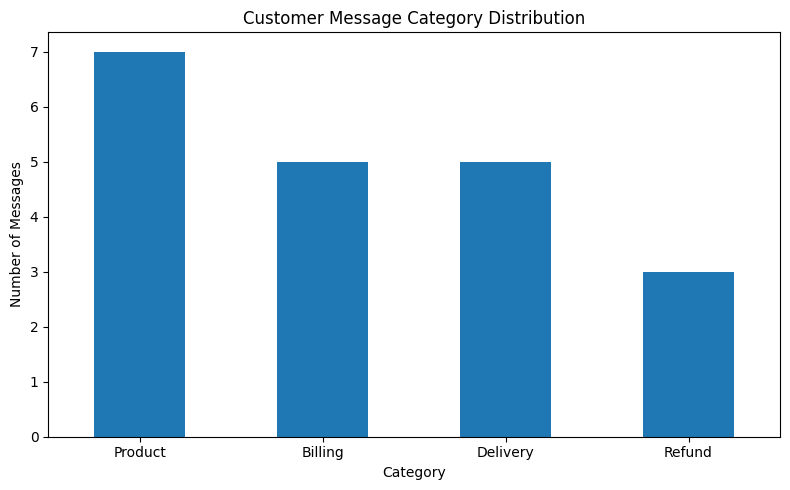

In [11]:
# Count the messages in each category

category_summary = df["Category"].value_counts()

# Create a bar chart
category_summary.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customer Message Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [12]:
# Add columns for human review

results["Human_Review"] = "Pending"
results["Corrected_Category"] = results["Predicted_Category"]

# Display the annotation results
results

,Customer_Message,Actual_Category,Predicted_Category,Prediction_Status,Human_Review,Corrected_Category
15,I was charged extra money,Billing,Product,Incorrect,Pending,Product
17,The parcel is missing,Delivery,Product,Incorrect,Pending,Product
11,The product quality is very poor,Product,Product,Correct,Pending,Product
2,I need to cancel and get a refund,Refund,Product,Incorrect,Pending,Product
19,I am unhappy with the product quality,Product,Product,Correct,Pending,Product


In [13]:
# Example of manually correcting the first result
# Only do this after checking the actual message.

results.loc[results.index[0], "Human_Review"] = "Reviewed"

# Change this label only if the reviewer confirms the correction
# results.loc[results.index[0], "Corrected_Category"] = "Refund"

results.head()

,Customer_Message,Actual_Category,Predicted_Category,Prediction_Status,Human_Review,Corrected_Category
15,I was charged extra money,Billing,Product,Incorrect,Reviewed,Product
17,The parcel is missing,Delivery,Product,Incorrect,Pending,Product
11,The product quality is very poor,Product,Product,Correct,Pending,Product
2,I need to cancel and get a refund,Refund,Product,Incorrect,Pending,Product
19,I am unhappy with the product quality,Product,Product,Correct,Pending,Product


In [14]:
# Save the results as a CSV file

results.to_csv("Text_Classification_Results.csv", index=False)

print("Dataset exported successfully!")

Dataset exported successfully!


In [15]:
# Download the CSV file

from google.colab import files

files.download("Text_Classification_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
print("TEXT CLASSIFICATION PROJECT")
print("---------------------------")

print("Total Messages:", len(df))
print("Number of Categories:", df["Category"].nunique())
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])
print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nProject completed successfully!")

TEXT CLASSIFICATION PROJECT
---------------------------
Total Messages: 20
Number of Categories: 4
Training Samples: 15
Testing Samples: 5
Model Accuracy: 40.0 %

Project completed successfully!
